In [26]:
import glob
import os
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics import YOLO
import pandas as pd

import sys
sys.path.append("..")
sys.path.append("../../objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator
import utils
from tflite_inference import TFLiteInferer
from tflite_inference_input_adapter import TFLiteInferenceWithInputAdapter


pd.options.display.float_format = '{:.3f}'.format
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.set_option('max_colwidth', 1000)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
TUNED_CONF_TH = 0.35
TUNED_IOU_TH = 0.5

INPUT_WIDTH = 320
INPUT_HEIGHT = 320

BASE_DATASET_PTH = os.path.abspath("./cam4_poc_15")
SUBSET_NAME = "val"

IMGS_PTH = os.path.join(BASE_DATASET_PTH, "images", SUBSET_NAME)
LABELS_PTH = os.path.join(BASE_DATASET_PTH, "labels", SUBSET_NAME)

DATASET_PTH = os.path.join(BASE_DATASET_PTH, "project_pg.yaml")

WEIGHTS_PTH = "../results/filtered_v3_margin_15_gaussian_noise/weights/best.pt"
# WEIGHTS_PTH = "../results/filtered_v3_margin_15/weights/best.pt"

PROJECT = os.path.join(os.getcwd(), "val")
# EXP_NAME = "candidateB_grayscale_blurred_baseline"
EXP_NAME = "candidateB_yolov8_preprocessing"
# EXP_NAME = "candidateB_yolov_preprocessing_yolo"
PREDICTIONS_PTH = os.path.join(PROJECT, EXP_NAME, "predictions.json")

In [28]:
# font 
font = cv2.FONT_HERSHEY_SIMPLEX 
  
# fontScale 
fontScale = 0.85
  
# Line thickness of 2 px 
thickness = 3

colors = {
    utils.BBType.GroundTruth: (0, 255, 0),
    utils.BBType.Detected: (0, 0, 255)
}

In [29]:
inferer = TFLiteInferenceWithInputAdapter(
    yolo_pth="../results/filtered_v3_margin_15_reduced_quality/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/filtered_v3_margin_15_reduced_quality/weights/head_saved_model/head_float32.tflite",
    adapter_pth="../input_adapter/input_adapter_full_integer_quant.tflite",
    conf_th=TUNED_CONF_TH,
    iou_th=TUNED_IOU_TH,
    imgsz=INPUT_WIDTH,
)

In [30]:
if not os.path.exists(PREDICTIONS_PTH):
    os.makedirs(os.path.dirname(PREDICTIONS_PTH), exist_ok=True)

    predictions = []
    for img_pth in tqdm(glob.glob(os.path.join(IMGS_PTH, "*.jpg"))):
        img_name = os.path.basename(img_pth)
        img = cv2.imread(img_pth)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        detections = inferer.infer(img)
        for det in detections:
            predictions.append({
                "image_id": img_name,
                "category_id": int(det[5]),
                "bbox": det[:4].tolist(),
                "keypoints": det[-2:].tolist(),
                "score": det[4].tolist(),
            })
    
    with open(PREDICTIONS_PTH, "wt") as f:
        json.dump(predictions, f)

with open(PREDICTIONS_PTH, "rt") as f:
    predictions = json.load(f)

  0%|          | 0/191 [00:00<?, ?it/s]

100%|██████████| 191/191 [00:07<00:00, 25.57it/s]


In [31]:
# model = YOLO(WEIGHTS_PTH)
# if not os.path.exists(PREDICTIONS_PTH):
#     metrics = model.val(
#         data=DATASET_PTH,
#         task="pose",
#         device=[0],
#         batch=64,
#         verbose=True,
#         conf=TUNED_CONF_TH,
#         iou=TUNED_IOU_TH,
#         project=PROJECT,
#         name=EXP_NAME,
#         exist_ok=True,
#         save_json=True,
#     )


# with open(PREDICTIONS_PTH, "rt") as f:
#     predictions = json.load(f)

In [32]:
def plot_img(img_id:str, predictions: dict[str, list]) -> np.ndarray:
    # img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}.jpg"))
    img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}"))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_h, img_w, _ = img.shape
    
    color = colors[utils.BBType.GroundTruth]
    # label_pth = os.path.join(LABELS_PTH, f"{img_id}.txt")
    label_pth = os.path.join(LABELS_PTH, f"{img_id.replace('.jpg', '.txt')}")
    with open(label_pth, "rt") as f:
        lines = f.readlines()
    for line in lines:
        _, x_c, y_c, w, h, x, y = [float(i) for i in line[:-1].split()]
        
        p1 = [int((x_c - w / 2) * img_w), int((y_c - h / 2) * img_h)]
        p2 = [int((x_c + w / 2) * img_w), int((y_c + h / 2) * img_h)]
        point = [int(x * img_w), int(y * img_h)]
        cv2.rectangle(img, p1, p2, color, 2)
        cv2.circle(img, point, 6, color, 10)
        
        


    color = colors[utils.BBType.Detected]
    for prediction in predictions[img_id]:
        bbox = np.array(prediction["bbox"]).astype(int)
        
        cv2.rectangle(img, bbox[:2], bbox[:2] + bbox[2:], color, 2)
        
        point = np.array(prediction["keypoints"]).astype(int)
        cv2.circle(img, point, 6, color, 10)
        
        cv2.rectangle(img, bbox[:2], bbox[:2] + [75, 40], color, -1)
        cv2.putText(img, f"{prediction['score']:.02f}", bbox[:2] + [5, 25], font, fontScale, (255, 255, 255), thickness, cv2.LINE_AA) 

    return img

In [33]:
predictions_by_id = {}
for prediction in predictions:
    img_id = prediction["image_id"]
    if img_id in predictions_by_id:
        predictions_by_id[img_id].append(prediction)
    else:
        predictions_by_id[img_id] = [prediction]

len(predictions_by_id)

180

In [34]:
metrics_pth = os.path.join(PROJECT, EXP_NAME, "metrics_per_img.csv")

if os.path.exists(metrics_pth):
    metrics = pd.read_csv(metrics_pth)
else:

    # init evaluator
    img_sizes: dict[str, tuple] = {}

    metrics = []

    common_evaluator = MetricsEvaluator(
            is_relative_coordinates=True,
            is_xywh_coordinates=True,
            img_size=(INPUT_WIDTH, INPUT_HEIGHT),
            outpath="."
        )

    for img_id, predictions in tqdm(predictions_by_id.items(), total=len(predictions_by_id)):
        evaluator = MetricsEvaluator(
            is_relative_coordinates=True,
            is_xywh_coordinates=True,
            img_size=(INPUT_WIDTH, INPUT_HEIGHT),
            outpath="."
        )

        img_size = img_sizes.get(img_id, None)
        if img_size is None:
            # img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}.jpg"))
            img = cv2.imread(os.path.join(IMGS_PTH, f"{img_id}"))
            img_h, img_w, _ = img.shape
            img_sizes[img_id] = (img_h, img_w)
        else:
            img_h, img_w = img_size

        # label_pth = os.path.join(LABELS_PTH, f"{img_id}.txt")
        label_pth = os.path.join(LABELS_PTH, f"{img_id.replace('.jpg', '.txt')}")
        with open(label_pth, "rt") as f:
            lines = f.readlines()
        for line in lines:
            c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
            if c > 1:
                continue
            if np.isnan(x_c):
                continue
            
            evaluator.add_gt_box(
                img_path=img_id,
                class_name="person",
                bbox=[x_c, y_c, w, h]
            )
            common_evaluator.add_gt_box(
                img_path=img_id,
                class_name="person",
                bbox=[x_c, y_c, w, h]
            )

        for prediction in predictions:
            x, y, w, h = np.array(prediction["bbox"]) / [img_w, img_h, img_w, img_h]

            evaluator.add_det_box(
                img_path=img_id,
                class_name="person",
                bbox=[x + w/2, y + h/2, w, h],
                confidence=prediction["score"]
            )
            common_evaluator.add_det_box(
                img_path=img_id,
                class_name="person",
                bbox=[x + w/2, y + h/2, w, h],
                confidence=prediction["score"]
            )


        result = evaluator.eval_conf_vals(0.5)[0]
        precision = result["total TP"] / (result["total TP"] + result["total FP"])
        recall = result["total TP"] / (result["total positives"])
        f_score = 2 * precision * recall / (precision + recall + 1e-9)
        metrics.append({
            "img_id": img_id,
            "P": precision,
            "R": recall,
            "F1": f_score,
            "AP": result['AP']
        })

    metrics = pd.DataFrame(metrics)
    metrics.to_csv(metrics_pth, index=False)

    results = common_evaluator.eval_conf_vals(0.5)
    for result in results:
        precision = result["total TP"] / (result["total TP"] + result["total FP"])
        recall = result["total TP"] / (result["total positives"])

        f_score = 2 * precision * recall / (precision + recall)
        print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

print("=============================================")
print(metrics.head())
print("=============================================")
print("Avg:")
print(metrics[["P", "R", "F1", "AP"]].mean())

  0%|          | 0/180 [00:00<?, ?it/s]

/tmp/ipykernel_821058/4112791670.py:77: RuntimeWarning: invalid value encountered in scalar divide
  recall = result["total TP"] / (result["total positives"])
100%|██████████| 180/180 [00:00<00:00, 347.71it/s]

person: P = 0.910. R = 0.795. F1 = 0.849. AP = 0.791
                  img_id     P     R    F1    AP
0     250_cam4_cam46.jpg 1.000 1.000 1.000 1.000
1     250_cam4_cam16.jpg 1.000 1.000 1.000 1.000
2    250h_cam4_cam36.jpg 1.000 0.333 0.500 0.333
3  4pplwalking-cam28.jpg 1.000 1.000 1.000 1.000
4              cam20.jpg 0.500 1.000 0.667 1.000
Avg:
P    0.898
R    0.802
F1   0.819
AP   0.794
dtype: float64


In [35]:
# person: P = 0.826. R = 0.726. F1 = 0.773. AP = 0.719
# person: P = 0.937. R = 0.695. F1 = 0.798. AP = 0.689 - baseline model

In interval (-0.1, 0.0] number of cases =    6 ( 3.3%)


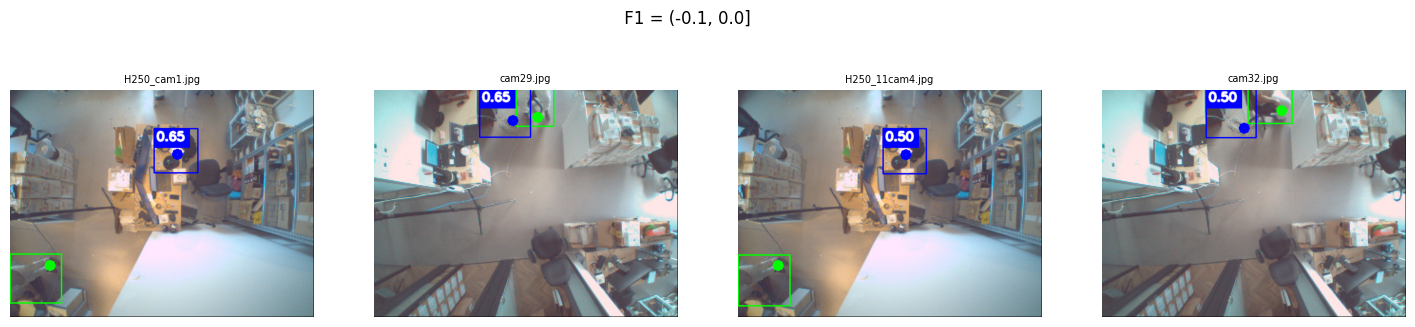

In interval ( 0.0, 0.1] number of cases =    0 ( 0.0%)
In interval ( 0.1, 0.2] number of cases =    0 ( 0.0%)
In interval ( 0.2, 0.3] number of cases =    0 ( 0.0%)
In interval ( 0.3, 0.4] number of cases =    2 ( 1.1%)


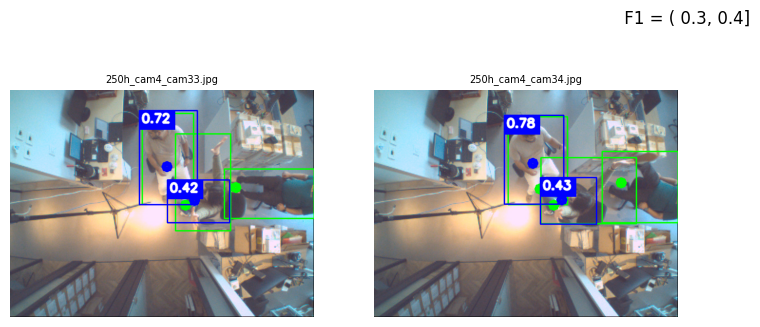

In interval ( 0.4, 0.5] number of cases =   17 ( 9.4%)


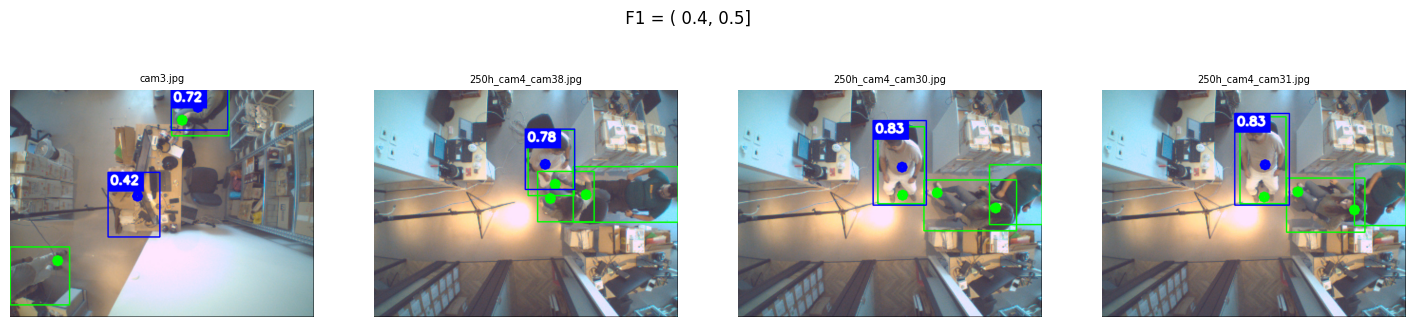

In interval ( 0.5, 0.6] number of cases =    1 ( 0.6%)


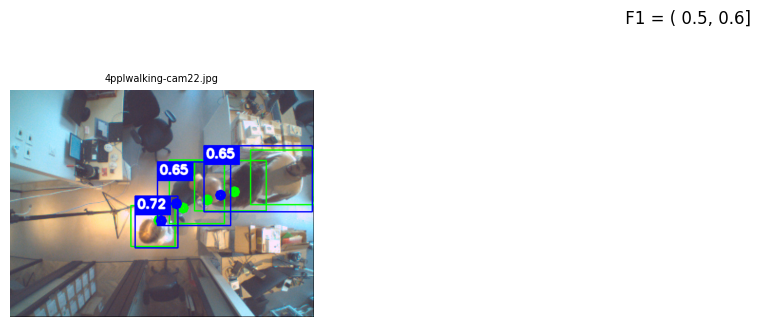

In interval ( 0.6, 0.7] number of cases =   38 (21.1%)


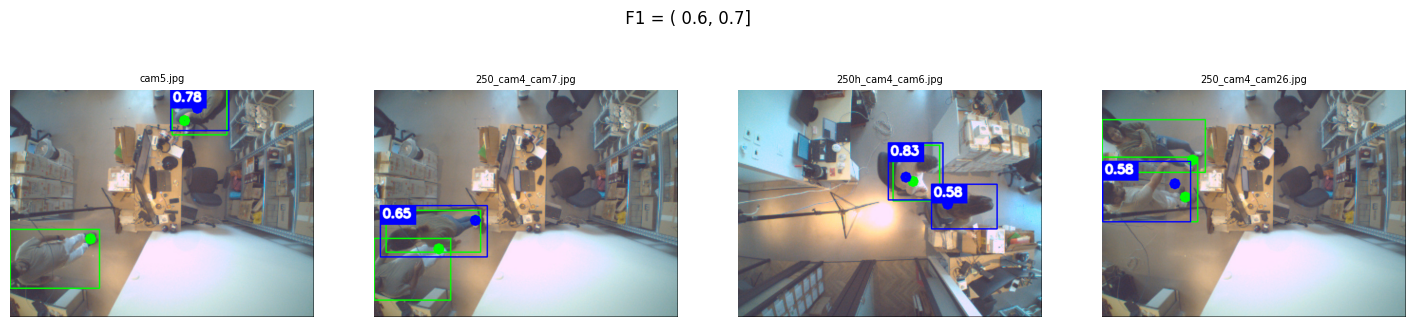

In interval ( 0.7, 0.8] number of cases =   12 ( 6.7%)


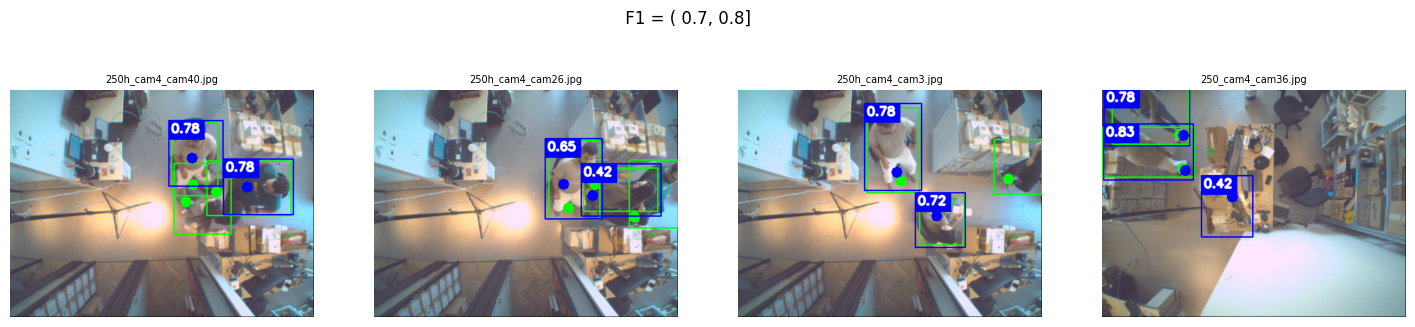

In interval ( 0.8, 0.9] number of cases =    8 ( 4.4%)


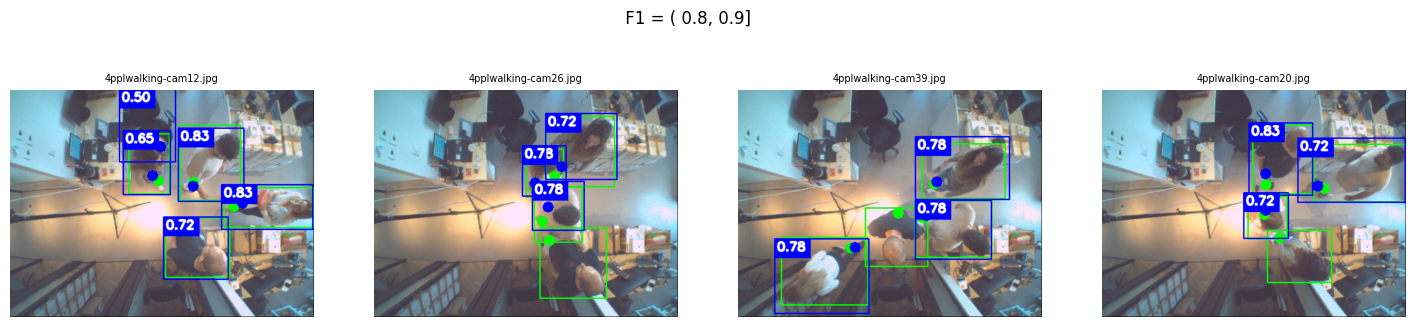

In interval ( 0.9, 1.0] number of cases =   95 (52.8%)


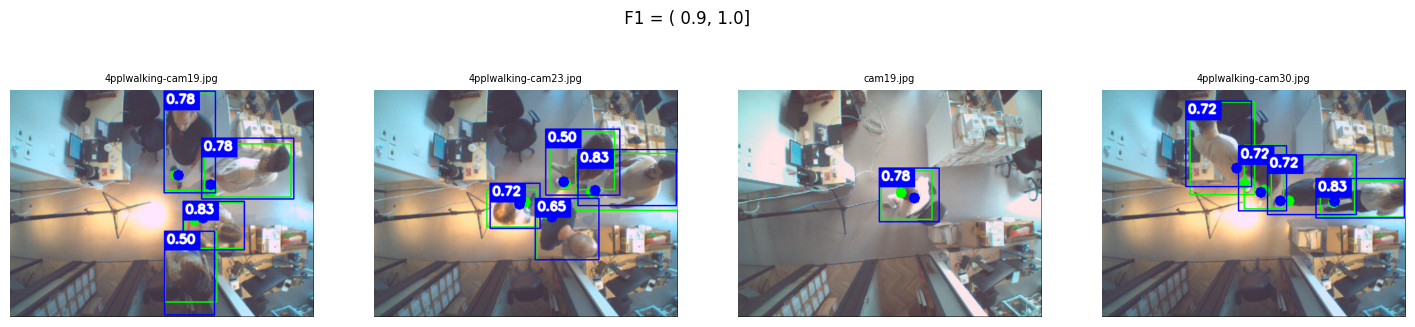

In [36]:
N = 4
ranges = np.arange(-0.1, 1.01, 0.1)
ranges

total_n = metrics.shape[0]
for i in range(len(ranges) - 1):
    img_ids = metrics[((metrics["F1"] > ranges[i])) & (metrics["F1"] <= ranges[i + 1])]["img_id"].values
    print(f"In interval ({ranges[i]:>4.01f}, {ranges[i + 1]:.01f}] number of cases = {img_ids.shape[0]:>4} ({img_ids.shape[0] / total_n * 100:>4.01f}%)")

    if len(img_ids) < 1:
        continue
    # np.random.seed(42)
    np.random.seed(11)
    np.random.shuffle(img_ids)
    
    plt.figure(figsize=(18, 4))
    plt.suptitle(f" F1 = ({ranges[i]:>4.01f}, {ranges[i + 1]:.01f}]")
    for i, img_id in enumerate(img_ids[:N]):
        plt.subplot(1, 4, i + 1)
        plt.imshow(plot_img(img_id, predictions_by_id))
        plt.title(img_id, fontsize=7)
        plt.axis('off')
    plt.show();


In [42]:
os.makedirs(os.path.join(PROJECT, EXP_NAME, "viz"), exist_ok=True)
for img_id in metrics["img_id"].values:
    img = plot_img(img_id, predictions_by_id)
    cv2.imwrite(os.path.join(PROJECT, EXP_NAME, "viz", img_id), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

In [41]:
os.path.join(PROJECT, EXP_NAME, "viz")

'/home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/val/candidateB_yolov8_preprocessing/viz'